# Comparing Extended KNN (v2) vs K-Means
Benchmarking our algo with adaptive thresholding against K-Means across non-convex and convex geometries.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_circles, make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

from v2_global import ExtendedKNN

In [2]:
X_moons, y_moons = make_moons(n_samples=300, noise=0.07, random_state=42)
X_moons = StandardScaler().fit_transform(X_moons)

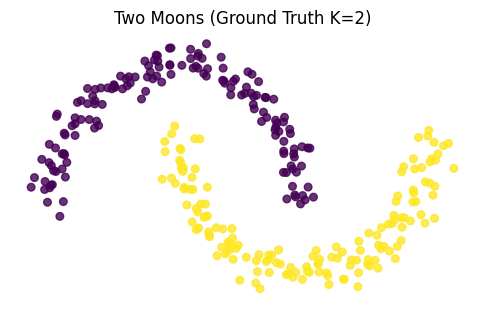

In [3]:
plt.figure(figsize=(6, 3.5))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap='viridis', s=30, alpha=0.8)
plt.title("Two Moons (Ground Truth K=2)")
plt.axis('off')
plt.show()

In [4]:
# K-Means on Moons (given true K=2)
km_moons = KMeans(n_clusters=2, random_state=42)
y_km_moons = km_moons.fit_predict(X_moons)
ari_km_moons = adjusted_rand_score(y_moons, y_km_moons)
print(f"K-Means Moons ARI: {ari_km_moons:.3f}")

K-Means Moons ARI: 0.479


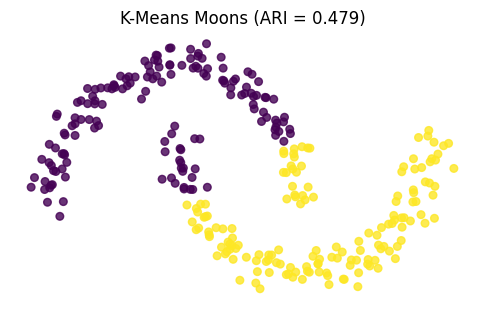

In [5]:
plt.figure(figsize=(6, 3.5))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_km_moons, cmap='viridis', s=30, alpha=0.8)
plt.title(f"K-Means Moons (ARI = {ari_km_moons:.3f})")
plt.axis('off')
plt.show()

In [ ]:
# Our Algo on Moons (X only, cuz the algo discovers K on the own )
np.random.seed(42)
model_moons = ExtendedKNN(X_moons, w=3.5)
model_moons.fit()

ari_v2_moons = adjusted_rand_score(y_moons, model_moons.Labels)
print(f"Extended KNN v2 Moons ARI: {ari_v2_moons:.3f}")
print("Clusters found:", len(model_moons.Clusters))
print("Cluster sizes:", [len(c) for c in model_moons.Clusters])

#In this notebook we only talk about w=3.5 (cuz we have tested and it gave the best results) , in the next one we have discessed the algo on different weights

Extended KNN v2 Moons ARI: 0.987
Clusters found: 3
Cluster sizes: [2, 150, 148]


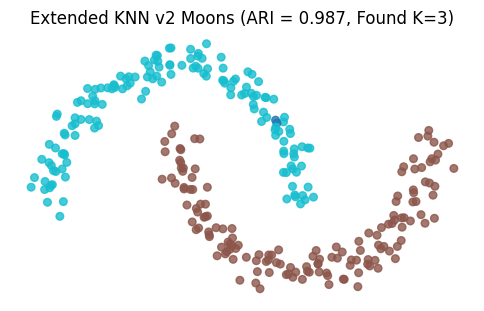

In [7]:
plt.figure(figsize=(6, 3.5))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=model_moons.Labels, cmap='tab10', s=30, alpha=0.8)
plt.title(f"Extended KNN v2 Moons (ARI = {ari_v2_moons:.3f}, Found K={len(model_moons.Clusters)})")
plt.axis('off')
plt.show()

In [8]:
X_circ, y_circ = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=42)
X_circ = StandardScaler().fit_transform(X_circ)

In [9]:
# K-Means on Circles (given true K=2)
km_circ = KMeans(n_clusters=2, random_state=42)
y_km_circ = km_circ.fit_predict(X_circ)
ari_km_circ = adjusted_rand_score(y_circ, y_km_circ)
print(f"K-Means Circles ARI: {ari_km_circ:.3f}")

K-Means Circles ARI: -0.003


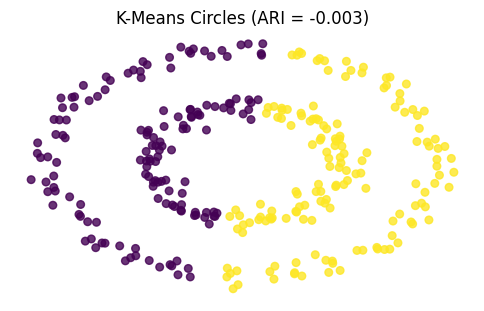

In [10]:
plt.figure(figsize=(6, 3.5))
plt.scatter(X_circ[:, 0], X_circ[:, 1], c=y_km_circ, cmap='viridis', s=30, alpha=0.8)
plt.title(f"K-Means Circles (ARI = {ari_km_circ:.3f})")
plt.axis('off')
plt.show()

In [ ]:
# Our algo on Concentric circles
np.random.seed(42)
model_circ = ExtendedKNN(X_circ, w=3.5)
model_circ.fit()

ari_v2_circ = adjusted_rand_score(y_circ, model_circ.Labels)
print(f"Extended KNN v2 Circles ARI: {ari_v2_circ:.3f}")
print("Clusters found:", len(model_circ.Clusters))
print("Cluster sizes:", [len(c) for c in model_circ.Clusters])

Extended KNN v2 Circles ARI: 0.987
Clusters found: 3
Cluster sizes: [2, 150, 148]


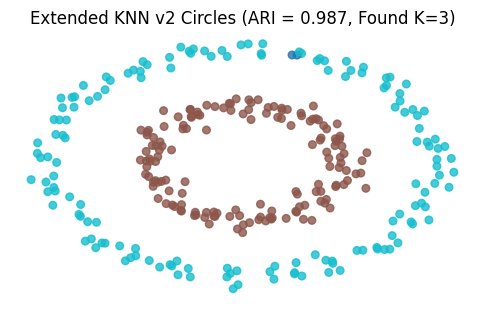

In [12]:
plt.figure(figsize=(6, 3.5))
plt.scatter(X_circ[:, 0], X_circ[:, 1], c=model_circ.Labels, cmap='tab10', s=30, alpha=0.8)
plt.title(f"Extended KNN v2 Circles (ARI = {ari_v2_circ:.3f}, Found K={len(model_circ.Clusters)})")
plt.axis('off')
plt.show()

In [13]:
X_blobs, y_blobs = make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=42)
X_blobs = StandardScaler().fit_transform(X_blobs)

In [14]:
# K-Means on Blobs (given true K=3)
km_blobs = KMeans(n_clusters=3, random_state=42)
y_km_blobs = km_blobs.fit_predict(X_blobs)
ari_km_blobs = adjusted_rand_score(y_blobs, y_km_blobs)
print(f"K-Means Blobs ARI: {ari_km_blobs:.3f}")

K-Means Blobs ARI: 1.000


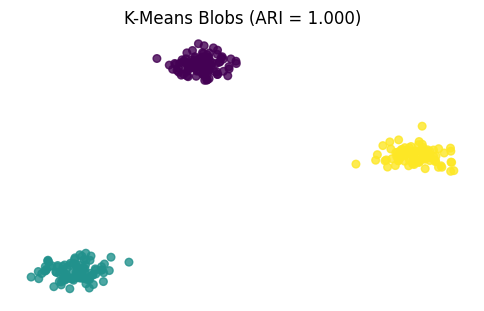

In [15]:
plt.figure(figsize=(6, 3.5))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=y_km_blobs, cmap='viridis', s=30, alpha=0.8)
plt.title(f"K-Means Blobs (ARI = {ari_km_blobs:.3f})")
plt.axis('off')
plt.show()

In [ ]:
# Our algo on Blobs (X only, discovers K)
np.random.seed(42)
model_blobs = ExtendedKNN(X_blobs, w=3.5)
model_blobs.fit()

ari_v2_blobs = adjusted_rand_score(y_blobs, model_blobs.Labels)
print(f"Extended KNN v2 Blobs ARI: {ari_v2_blobs:.3f}")
print("Clusters found:", len(model_blobs.Clusters))
print("Cluster sizes:", [len(c) for c in model_blobs.Clusters])

#KMC performs better , but yet again we had to provide it with the number of clusters in the first place 

Extended KNN v2 Blobs ARI: 0.980
Clusters found: 5
Cluster sizes: [98, 99, 99, 2, 2]


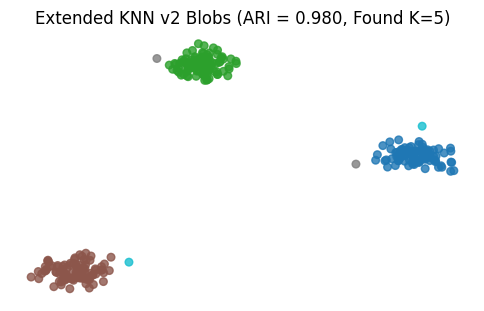

In [17]:
plt.figure(figsize=(6, 3.5))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=model_blobs.Labels, cmap='tab10', s=30, alpha=0.8)
plt.title(f"Extended KNN v2 Blobs (ARI = {ari_v2_blobs:.3f}, Found K={len(model_blobs.Clusters)})")
plt.axis('off')
plt.show()

In [19]:
summary = [
    ('Moons',   2, ari_km_moons, len(model_moons.Clusters), ari_v2_moons),
    ('Circles', 2, ari_km_circ,  len(model_circ.Clusters),  ari_v2_circ),
    ('Blobs',   3, ari_km_blobs, len(model_blobs.Clusters), ari_v2_blobs)
]

print(f"{'Dataset':<10} {'True K':<8} {'KMeans ARI':<12} {'V2 Found K':<12} {'V2 ARI':<8}")
print('-' * 52)
for name, tk, k_ari, v_k, v_ari in summary:
    print(f"{name:<10} {tk:<8} {k_ari:<12.3f} {v_k:<12} {v_ari:<8.3f}")

Dataset    True K   KMeans ARI   V2 Found K   V2 ARI  
----------------------------------------------------
Moons      2        0.479        3            0.987   
Circles    2        -0.003       3            0.987   
Blobs      3        1.000        5            0.980   
